# Process Mining: процесс выдачи потребительского кредита

Журнал событий [BPI Challenge 2017](https://data.4tu.nl/articles/_/12696884/1): 31 509 заявок и 1,2 млн событий нидерландского банка за 2016 год. Задача — восстановить фактический процесс, найти потери и отклонения от нормы.

**Выводы**
- Исходы: 55% — кредит выдан, 33% — отмена, 12% — отказ банка.
- Крупнейшая потеря — автоматическая отмена: около 7 тыс. заявок (почти четверть) закрываются через 30 дней без ответа клиента на предложение.
- Доработка документов увеличивает медианный срок выдачи на 5,1–5,8 дня (95% ДИ).
- 95,6% заявок соответствуют эталонной модели. Среди отклонений — ~760 заявок, брошенных после запроса документов, и 99 отказов без этапа проверки.

[Дашборд в Yandex DataLens](https://datalens.yandex/t7e5c7ccnq0wc?_share_link=public)

In [1]:
!pip install -q pm4py

In [2]:
import glob
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pm4py
from scipy import stats

## 1. Данные

Файл `BPI Challenge 2017.xes.gz` с [4TU.ResearchData](https://data.4tu.nl/articles/_/12696884/1) (CC BY 4.0), подключён как Kaggle Dataset.

In [3]:
path = glob.glob('/kaggle/input/**/*.xes*', recursive=True)[0]
log = pm4py.read_xes(path)  # читается несколько минут

print('заявок:', log['case:concept:name'].nunique())
print('событий:', len(log))
print('период:', log['time:timestamp'].min(), '—', log['time:timestamp'].max())
print()
print(log['concept:name'].value_counts().to_string())

заявок: 31509
событий: 1202267
период: 2016-01-01 09:51:15.304000+00:00 — 2017-02-01 14:11:03.499000+00:00

concept:name
W_Validate application        209496
W_Call after offers           191092
W_Call incomplete files       168529
W_Complete application        148900
W_Handle leads                 47264
O_Create Offer                 42995
O_Created                      42995
O_Sent (mail and online)       39707
A_Validating                   38816
A_Accepted                     31509
A_Create Application           31509
A_Concept                      31509
A_Complete                     31362
O_Returned                     23305
A_Incomplete                   23055
O_Cancelled                    20898
A_Submitted                    20423
O_Accepted                     17228
A_Pending                      17228
A_Cancelled                    10431
O_Refused                       4695
A_Denied                        3753
W_Assess potential fraud        3282
O_Sent (online only)        

Для карты процесса используются статусы заявки (`A_`). Каждая заявка проходит `Create → Concept → Accepted`, исход — `A_Pending` (выдача), `A_Denied` (отказ) или `A_Cancelled` (отмена). События предложений (`O_`) и задач сотрудников (`W_`) в карту не включаются.

Пример заявки:

In [4]:
first = log['case:concept:name'].iloc[0]
cols = ['concept:name', 'time:timestamp', 'org:resource', 'lifecycle:transition']
log.loc[log['case:concept:name'] == first, cols]

,concept:name,time:timestamp,org:resource,lifecycle:transition
0,A_Create Application,2016-01-01 09:51:15.304000+00:00,User_1,complete
1,A_Submitted,2016-01-01 09:51:15.352000+00:00,User_1,complete
2,W_Handle leads,2016-01-01 09:51:15.774000+00:00,User_1,schedule
3,W_Handle leads,2016-01-01 09:52:36.392000+00:00,User_1,withdraw
4,W_Complete application,2016-01-01 09:52:36.403000+00:00,User_1,schedule
5,A_Concept,2016-01-01 09:52:36.413000+00:00,User_1,complete
6,W_Complete application,2016-01-02 10:45:22.429000+00:00,User_17,start
7,W_Complete application,2016-01-02 10:49:28.816000+00:00,User_17,suspend
8,A_Accepted,2016-01-02 11:23:04.299000+00:00,User_52,complete
9,O_Create Offer,2016-01-02 11:29:03.994000+00:00,User_52,complete


## 2. Исходы и переходы

Журнал загружен в SQLite; длительности переходов между статусами посчитаны через `LAG` в разрезе заявки.

In [5]:
events = log[['case:concept:name', 'concept:name', 'time:timestamp', 'lifecycle:transition',
              'org:resource', 'case:LoanGoal', 'case:ApplicationType', 'case:RequestedAmount']].copy()
events.columns = ['case_id', 'activity', 'ts', 'lifecycle', 'resource', 'loan_goal', 'app_type', 'amount']
events['ts'] = events['ts'].dt.tz_localize(None).astype(str)  # SQLite хранит время текстом

con = sqlite3.connect('bpi.db')
events.to_sql('events', con, index=False, if_exists='replace')

1202267

In [6]:
q_outcomes = '''
WITH cases AS (
    SELECT case_id,
           CASE WHEN SUM(activity = 'A_Pending') > 0 THEN 'кредит выдан'
                WHEN SUM(activity = 'A_Denied') > 0 THEN 'отказ банка'
                WHEN SUM(activity = 'A_Cancelled') > 0 THEN 'отменена'
                ELSE 'в работе' END AS outcome,
           julianday(MAX(ts)) - julianday(MIN(ts)) AS days
    FROM events
    GROUP BY case_id
)
SELECT outcome,
       COUNT(*) AS n,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct,
       ROUND(AVG(days), 1) AS avg_days
FROM cases
GROUP BY outcome
ORDER BY n DESC
'''
print(pd.read_sql(q_outcomes, con).to_string(index=False))

     outcome     n  pct  avg_days
кредит выдан 17228 54.7      18.1
    отменена 10431 33.1      29.9
 отказ банка  3752 11.9      16.8
    в работе    98  0.3      28.7


In [7]:
q_transitions = '''
WITH a AS (
    SELECT case_id, activity, ts,
           LAG(activity) OVER (PARTITION BY case_id ORDER BY ts) AS prev_activity,
           LAG(ts)       OVER (PARTITION BY case_id ORDER BY ts) AS prev_ts
    FROM events
    WHERE substr(activity, 1, 2) = 'A_'
)
SELECT prev_activity || ' → ' || activity AS transition,
       COUNT(*) AS n,
       ROUND(AVG(julianday(ts) - julianday(prev_ts)), 2) AS avg_days
FROM a
WHERE prev_activity IS NOT NULL
GROUP BY transition
ORDER BY n DESC
LIMIT 15
'''
print(pd.read_sql(q_transitions, con).to_string(index=False))

                        transition     n  avg_days
            A_Concept → A_Accepted 31509      1.42
           A_Accepted → A_Complete 31362      0.13
       A_Validating → A_Incomplete 23052      1.66
         A_Complete → A_Validating 21870      9.83
           A_Submitted → A_Concept 20423      0.05
A_Create Application → A_Submitted 20423      0.00
       A_Incomplete → A_Validating 16939      2.86
          A_Validating → A_Pending 12291      1.44
  A_Create Application → A_Concept 11086      0.00
          A_Complete → A_Cancelled  9307     28.36
          A_Incomplete → A_Pending  4937      5.88
           A_Validating → A_Denied  3373      2.80
        A_Incomplete → A_Cancelled   924     15.16
           A_Incomplete → A_Denied   210      2.14
             A_Complete → A_Denied   132      6.24


- Отменённые заявки самые долгие, в среднем 30 дней; переход `Complete → Cancelled` — 28 дней.
- На пути к выдаче дольше всего ожидание документов от клиента: `Complete → Validating`, около 10 дней.
- Документы возвращались на доработку 23 тыс. раз.
- Два входа в процесс: 20 тыс. заявок проходят через `A_Submitted` (предположительно онлайн-подача), 11 тыс. сразу попадают в `A_Concept`.

## 3. Карта процесса

Частотный и временной (медиана) графы прямых следований по статусам заявки.

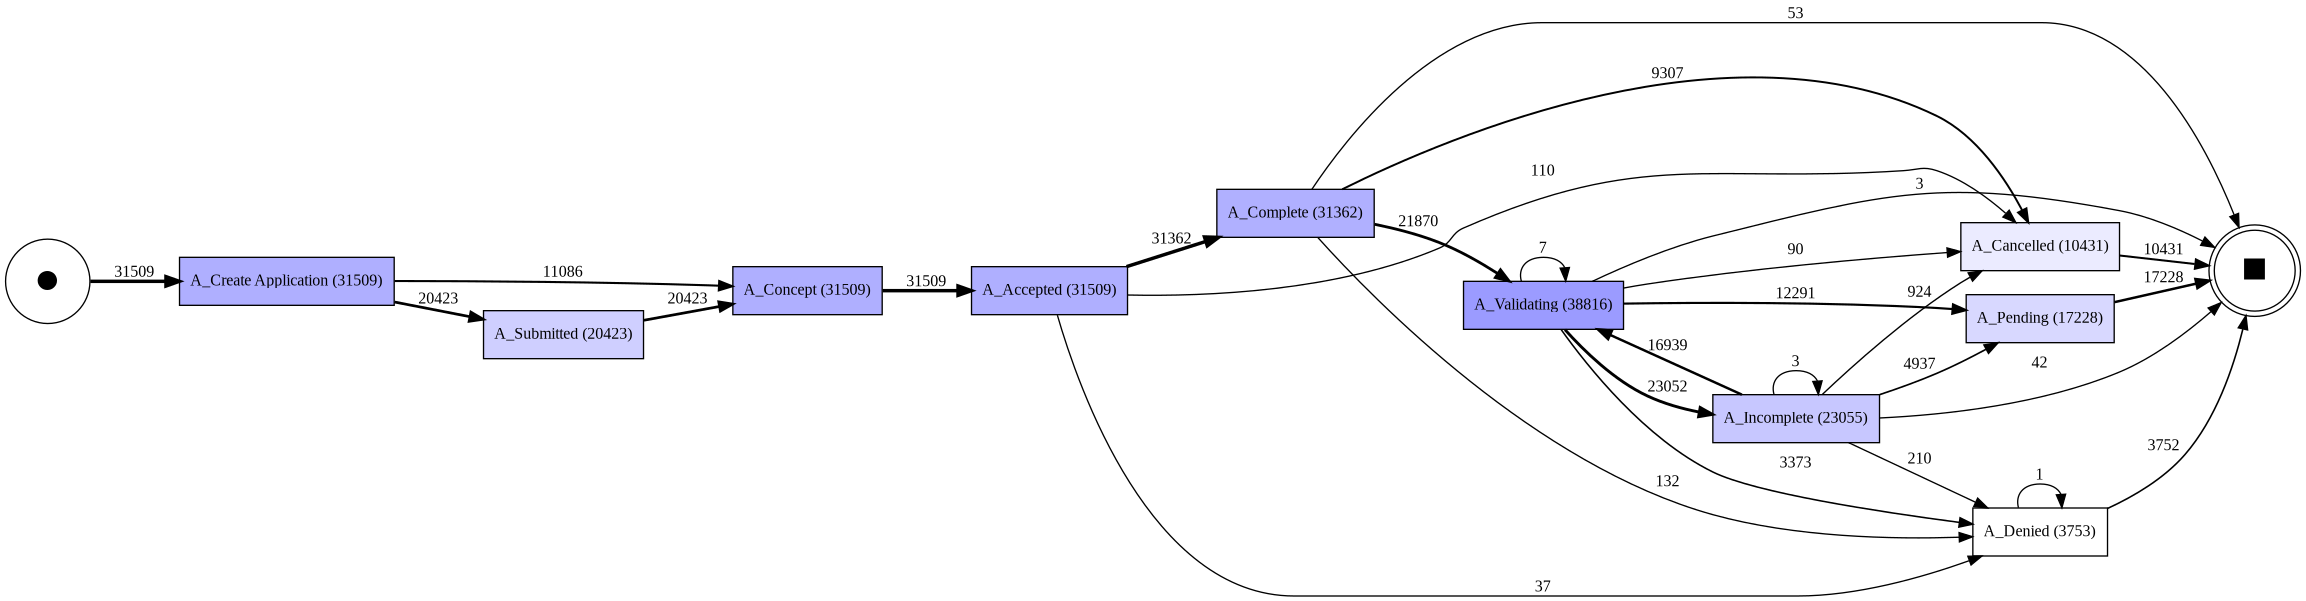

In [8]:
a_log = log[log['concept:name'].str.startswith('A_')].copy()

dfg, start, end = pm4py.discover_dfg(a_log)
pm4py.view_dfg(dfg, start, end)

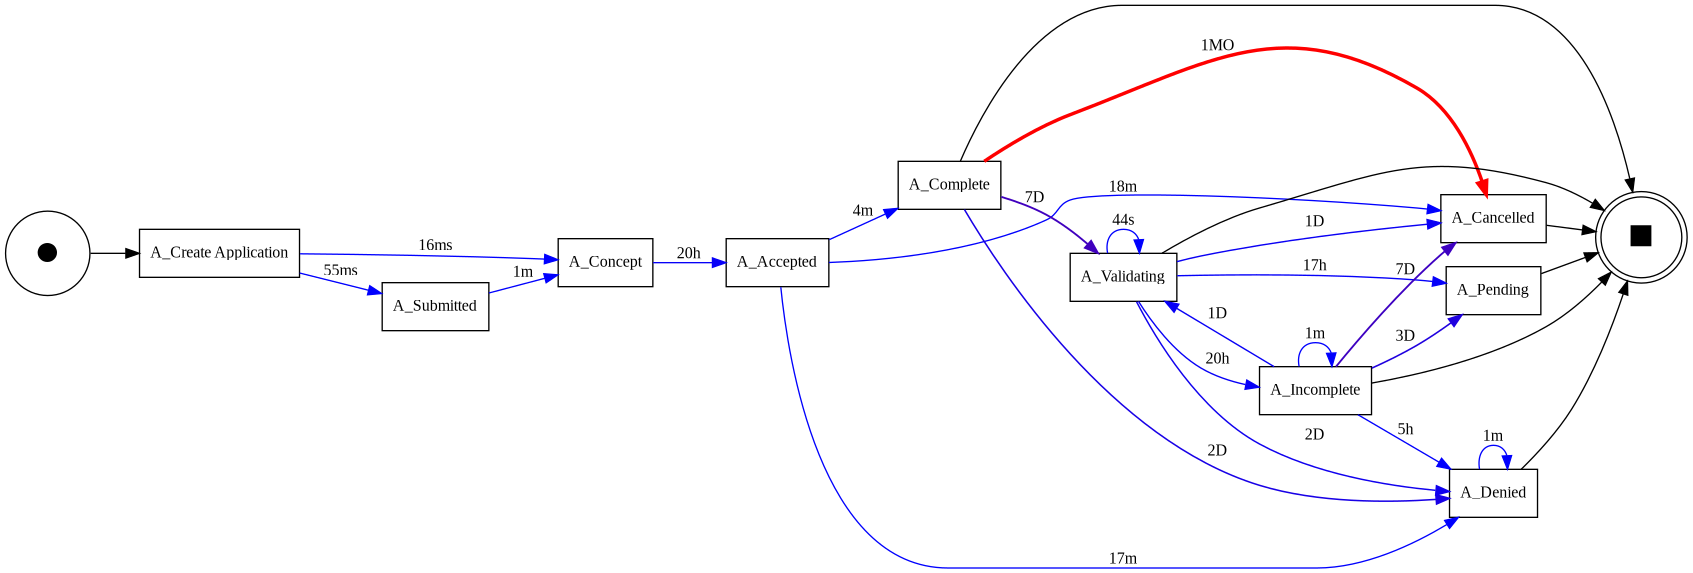

In [9]:
perf_dfg, start, end = pm4py.discover_performance_dfg(a_log)
pm4py.view_performance_dfg(perf_dfg, start, end, aggregation_measure='median')

Варианты процесса:

In [10]:
case_variant = (a_log.sort_values('time:timestamp')
                     .groupby('case:concept:name')['concept:name']
                     .agg(lambda s: ' → '.join(a.removeprefix('A_') for a in s)))
variants = case_variant.value_counts()
print('всего вариантов:', len(variants))
print('доля заявок в топ-10 вариантах:', round(variants.head(10).sum() / variants.sum(), 3))
print()
print((variants.head(10) / variants.sum()).round(3).to_string())

всего вариантов: 102
доля заявок в топ-10 вариантах: 0.778

concept:name
Create Application → Submitted → Concept → Accepted → Complete → Cancelled                                                                   0.217
Create Application → Submitted → Concept → Accepted → Complete → Validating → Incomplete → Validating → Pending                              0.094
Create Application → Concept → Accepted → Complete → Cancelled                                                                               0.078
Create Application → Submitted → Concept → Accepted → Complete → Validating → Pending                                                        0.073
Create Application → Concept → Accepted → Complete → Validating → Pending                                                                    0.072
Create Application → Concept → Accepted → Complete → Validating → Incomplete → Validating → Pending                                          0.068
Create Application → Submitted → Concept → Ac

- Самый долгий переход — `Complete → Cancelled`, медиана около месяца; на пути к выдаче — `Complete → Validating`, 7 дней.
- Петля `Validating ⇄ Incomplete` добавляет 1–3 дня за круг.
- 102 варианта, топ-10 покрывают 78% заявок. Самый частый (22%) — предложение отправлено, клиент не ответил, заявка отменена; вместе с тем же путём без `Submitted` это 30% заявок.

## 4. Узкие места

### 4.1. Отмены

Распределение времени от `A_Complete` до `A_Cancelled`: зависят ли отмены от поведения клиентов или от правила процесса.

count    10321.0
mean        28.4
std         11.7
min          0.0
25%         30.5
50%         30.7
75%         30.9
max        167.2


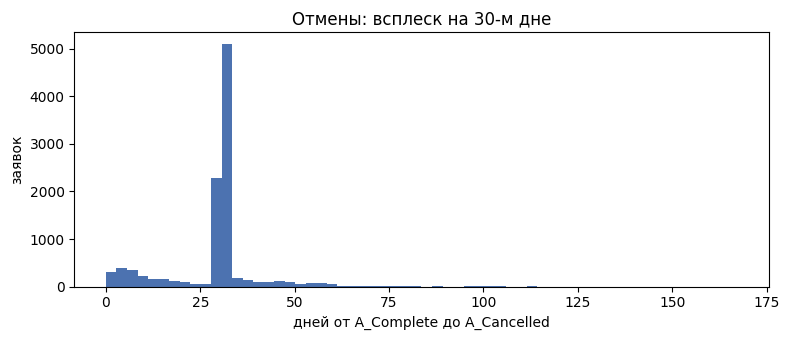

In [11]:
ev = a_log.sort_values('time:timestamp')[['case:concept:name', 'concept:name', 'time:timestamp']].copy()
ev.columns = ['case_id', 'activity', 'ts']

t_complete = ev[ev.activity == 'A_Complete'].groupby('case_id').ts.first()
t_cancel = ev[ev.activity == 'A_Cancelled'].groupby('case_id').ts.first()
wait = (t_cancel - t_complete).dropna().dt.total_seconds() / 86400
print(wait.describe().round(1).to_string())

plt.figure(figsize=(8, 3.5))
plt.hist(wait, bins=60, color='#4C72B0')
plt.xlabel('дней от A_Complete до A_Cancelled')
plt.ylabel('заявок')
plt.title('Отмены: всплеск на 30-м дне')
plt.tight_layout()
plt.show()

Половина отмен приходится на окно 30,5–30,9 дня: это отмена по таймауту, а не решение клиента. Так закрывается около 7 тыс. заявок.

### 4.2. Доработка документов

In [12]:
cases = ev.groupby('case_id').ts.agg(['min', 'max'])
cases['days'] = (cases['max'] - cases['min']).dt.total_seconds() / 86400
n_inc = ev[ev.activity == 'A_Incomplete'].groupby('case_id').size()
cases['n_incomplete'] = n_inc.reindex(cases.index).fillna(0).astype(int)


def has(activity):
    return cases.index.isin(ev.loc[ev.activity == activity, 'case_id'])


cases['outcome'] = np.select([has('A_Pending'), has('A_Denied'), has('A_Cancelled')],
                             ['выдан', 'отказ', 'отменена'], 'в работе')
cases['rework'] = np.where(cases.n_incomplete > 0, 'с доработкой', 'без доработки')

print('Все заявки:')
print(pd.crosstab(cases.rework, cases.outcome, normalize='index').round(3).to_string())

Все заявки:
outcome        в работе  выдан  отказ  отменена
rework                                         
без доработки     0.003  0.278  0.145     0.574
с доработкой      0.003  0.843  0.090     0.064


В наивном сравнении с доработкой кредит выдают втрое чаще, но группы несопоставимы: доработка возможна только у заявок, дошедших до проверки, а группа «без доработки» включает все заявки, отменённые по таймауту. Ниже сравниваются только заявки с `A_Validating`.

Заявки, дошедшие до проверки:
outcome        в работе  выдан  отказ  отменена
rework                                         
без доработки     0.000  0.667  0.324     0.009
с доработкой      0.003  0.843  0.090     0.064

Медиана дней до выдачи:
rework
без доработки    11.1
с доработкой     16.7


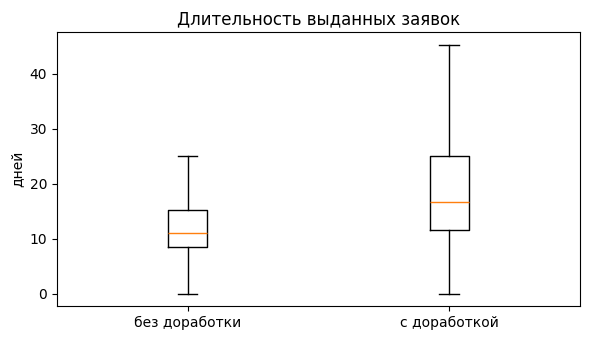

In [13]:
validated = cases[has('A_Validating')]
print('Заявки, дошедшие до проверки:')
print(pd.crosstab(validated.rework, validated.outcome, normalize='index').round(3).to_string())

issued = validated[validated.outcome == 'выдан']
print()
print('Медиана дней до выдачи:')
print(issued.groupby('rework').days.median().round(1).to_string())

groups = ['без доработки', 'с доработкой']
plt.figure(figsize=(6, 3.5))
plt.boxplot([issued.loc[issued.rework == g, 'days'] for g in groups], showfliers=False)
plt.xticks([1, 2], groups)
plt.ylabel('дней')
plt.title('Длительность выданных заявок')
plt.tight_layout()
plt.show()

Среди заявок, дошедших до проверки, доработка увеличивает медианный срок выдачи с 11,1 до 16,7 дня. Отказов с доработкой меньше (9% против 32%) — возможно, вместо отказа банк запрашивает документы; причинность этим не доказана.

## 5. Соответствие эталону

Эталонная модель построена inductive miner по 10 самым частым вариантам (78% заявок); каждая заявка проверена на соответствие через alignments.

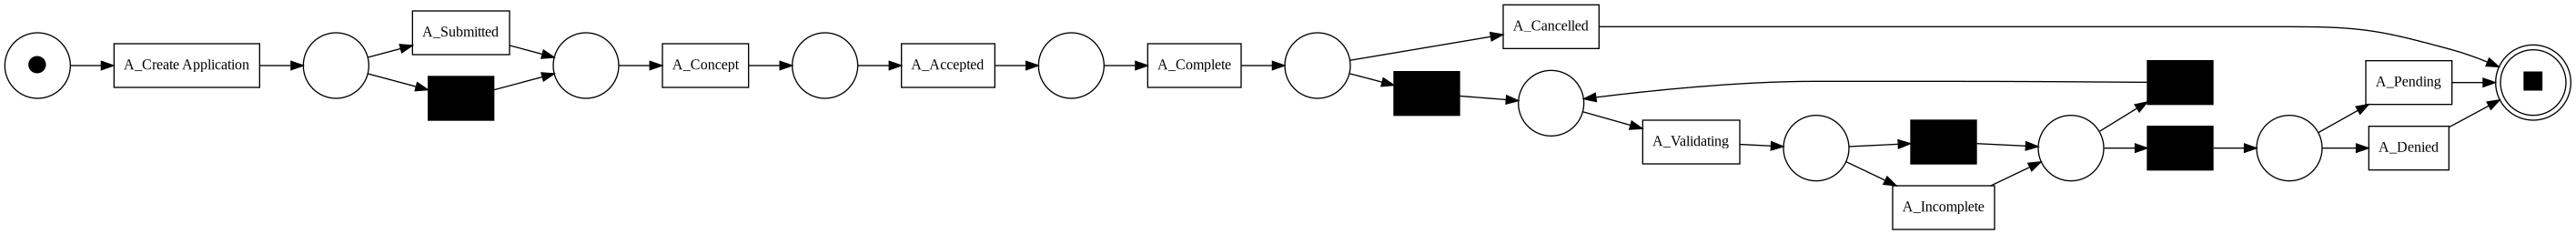

In [14]:
top = pm4py.filter_variants_top_k(a_log, 10)
net, im, fm = pm4py.discover_petri_net_inductive(top)
pm4py.view_petri_net(net, im, fm)

In [15]:
diag = pm4py.conformance_diagnostics_alignments(a_log, net, im, fm, return_diagnostics_dataframe=True)
cases['fit'] = diag.set_index('case_id').is_fit.reindex(cases.index).fillna(False).astype(bool)
cases['variant'] = case_variant

print('доля заявок по эталону:', round(cases.fit.mean(), 3))
print()
print(pd.crosstab(cases.fit, cases.outcome, normalize='index').round(3).to_string())
print()
print('частые отклонения:')
print(cases.loc[~cases.fit, 'variant'].value_counts().head(5).to_string())

доля заявок по эталону: 0.956

outcome  в работе  выдан  отказ  отменена
fit                                      
False        0.07  0.002  0.122     0.806
True         0.00  0.572  0.119     0.309

частые отклонения:
variant
Create Application → Submitted → Concept → Accepted → Complete → Validating → Incomplete → Cancelled                              397
Create Application → Concept → Accepted → Complete → Validating → Incomplete → Cancelled                                          213
Create Application → Submitted → Concept → Accepted → Complete → Validating → Incomplete → Validating → Incomplete → Cancelled    149
Create Application → Submitted → Concept → Accepted → Complete → Denied                                                            99
Create Application → Submitted → Concept → Accepted → Cancelled                                                                    73


95,6% заявок соответствуют эталону; 81% отклонений заканчиваются отменой. Две группы отклонений:
- ~760 заявок отменены после запроса документов (`Incomplete → Cancelled`) — потеря клиентов на доработке;
- 99 отказов без этапа проверки документов (`Complete → Denied`) — требуют проверки обоснованности.

## 6. Проверка гипотез

Срок выдачи с доработкой и без: критерий Манна–Уитни (распределения с длинным хвостом) и бутстрап-интервал для разницы медиан.

In [16]:
a = issued.loc[issued.rework == 'без доработки', 'days']
b = issued.loc[issued.rework == 'с доработкой', 'days']
u = stats.mannwhitneyu(a, b, alternative='two-sided')
print(f'n: {len(a)} и {len(b)}; медианы {a.median():.1f} и {b.median():.1f}; p-value = {u.pvalue:.2e}')

rng = np.random.default_rng(42)
diffs = [np.median(rng.choice(b.values, len(b))) - np.median(rng.choice(a.values, len(a)))
         for _ in range(2000)]
print('разница медиан, дней, 95% ДИ:', np.percentile(diffs, [2.5, 97.5]).round(2))

n: 4581 и 12647; медианы 11.1 и 16.7; p-value = 0.00e+00
разница медиан, дней, 95% ДИ: [5.1  5.81]


Доля отказов с доработкой и без, среди заявок, дошедших до проверки: хи-квадрат.

In [17]:
table = pd.crosstab(validated.rework, validated.outcome == 'отказ')
chi2, p, dof, expected = stats.chi2_contingency(table)
print(table.to_string())
print(f'chi2 = {chi2:.1f}, p-value = {p:.2e}')

outcome        False  True 
rework                     
без доработки   4640   2227
с доработкой   13647   1356
chi2 = 1880.0, p-value = 0.00e+00


Обе разницы значимы (p < 0.001). Доработка увеличивает медианный срок выдачи на 5,1–5,8 дня (95% ДИ). Связь доработки с долей отказов значима, но не означает, что доработка снижает отказы: группы могут различаться по составу клиентов.

## 7. Выгрузка для дашборда

Таблица заявок для [дашборда в DataLens](https://datalens.yandex/t7e5c7ccnq0wc?_share_link=public).

In [18]:
attrs = log.groupby('case:concept:name')[['case:LoanGoal', 'case:ApplicationType',
                                         'case:RequestedAmount']].first()
attrs.columns = ['loan_goal', 'app_type', 'amount']

export = cases[['days', 'outcome', 'rework', 'n_incomplete', 'fit', 'variant']].join(attrs)
export['month'] = cases['min'].dt.strftime('%Y-%m')
export = export.reset_index().rename(columns={'index': 'case_id'})
export.to_csv('cases.csv', index=False)
print(export.shape)

(31509, 11)


## Рекомендации

1. Напоминать клиенту о предложении до автоматической отмены, например на 20-й день, — это крупнейший источник потерь.
2. Выяснить, каких документов чаще всего не хватает, и запрашивать их при подаче: доработка добавляет к сроку выдачи 5–6 дней.
3. Проверить 99 отказов без этапа проверки документов.

Дальнейший анализ: разрез по цели кредита и каналу подачи, нагрузка сотрудников по задачам `W_`, модель раннего прогноза отмены.